# Taller — Abandono de producto financiero
Regresión logística en Python · Clase 9 · Machine Learning aplicado a Economía y Finanzas · FCEA · 2026-2

**Juan Diego Zutta Arcos**

Pregunta: dadas las características del cliente, ¿cuál es $P(\text{abandono}=1 \mid x)$? Se estima con `smf.logit` (y `smf.ols` como contraste), partición 70/30 con `default_rng(8)`.

## 1. Estructura de los datos

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from scipy.stats import chi2_contingency

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 20)

df_crudo = pd.read_csv("abandono_producto_financiero.csv", encoding="utf-8")
print("Dimensión cruda:", df_crudo.shape)
df_crudo.head()

Dimensión cruda: (10000, 14)


,numero_fila,id_cliente,apellido,puntaje_crediticio,pais,sexo,edad,antiguedad,saldo,numero_productos,tiene_tarjeta,miembro_activo,salario_estimado,abandono
0,1,15634602,Hargrave,619,Francia,Mujer,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,España,Mujer,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,Francia,Mujer,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,Francia,Mujer,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,España,Mujer,43,2,125510.82,1,1,1,79084.10,0


In [2]:
print(list(df_crudo.columns))
df_crudo.dtypes

['numero_fila', 'id_cliente', 'apellido', 'puntaje_crediticio', 'pais', 'sexo', 'edad', 'antiguedad', 'saldo', 'numero_productos', 'tiene_tarjeta', 'miembro_activo', 'salario_estimado', 'abandono']


numero_fila             int64
id_cliente              int64
apellido                  str
puntaje_crediticio      int64
pais                      str
sexo                      str
edad                    int64
antiguedad              int64
saldo                 float64
numero_productos        int64
tiene_tarjeta           int64
miembro_activo          int64
salario_estimado      float64
abandono                int64
dtype: object

In [3]:
df_crudo.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
numero_fila,10000.0,5000.50,2886.90,1.00,2500.75,5000.50,7500.25,10000.00
id_cliente,10000.0,15690940.57,71936.19,15565701.00,15628528.25,15690738.00,15753233.75,15815690.00
puntaje_crediticio,10000.0,650.53,96.65,350.00,584.00,652.00,718.00,850.00
edad,10000.0,38.92,10.49,18.00,32.00,37.00,44.00,92.00
antiguedad,10000.0,5.01,2.89,0.00,3.00,5.00,7.00,10.00
saldo,10000.0,76485.89,62397.41,0.00,0.00,97198.54,127644.24,250898.09
numero_productos,10000.0,1.53,0.58,1.00,1.00,1.00,2.00,4.00
tiene_tarjeta,10000.0,0.71,0.46,0.00,0.00,1.00,1.00,1.00
miembro_activo,10000.0,0.52,0.50,0.00,0.00,1.00,1.00,1.00
salario_estimado,10000.0,100090.24,57510.49,11.58,51002.11,100193.92,149388.25,199992.48


In [4]:
df = df_crudo.drop(columns=["numero_fila", "id_cliente", "apellido"]).copy()
df["pais"] = pd.Categorical(df["pais"], categories=["Francia", "Alemania", "España"])
df["sexo"] = pd.Categorical(df["sexo"], categories=["Mujer", "Hombre"])
df["abandono"] = df["abandono"].astype(int)

cuantitativas = ["puntaje_crediticio", "edad", "antiguedad", "saldo", "numero_productos", "salario_estimado"]
categoricas_binarias = ["pais", "sexo", "tiene_tarjeta", "miembro_activo", "abandono"]
print("Dimensión para el modelo:", df.shape)
print("Cuantitativas (", len(cuantitativas), "):", cuantitativas)
print("Categóricas o binarias (", len(categoricas_binarias), "):", categoricas_binarias)
print("Niveles de pais:", list(df["pais"].cat.categories), "· de sexo:", list(df["sexo"].cat.categories))
print("Faltantes totales:", int(df.isna().sum().sum()))
df.dtypes

Dimensión para el modelo: (10000, 11)
Cuantitativas ( 6 ): ['puntaje_crediticio', 'edad', 'antiguedad', 'saldo', 'numero_productos', 'salario_estimado']
Categóricas o binarias ( 5 ): ['pais', 'sexo', 'tiene_tarjeta', 'miembro_activo', 'abandono']
Niveles de pais: ['Francia', 'Alemania', 'España'] · de sexo: ['Mujer', 'Hombre']
Faltantes totales: 0


puntaje_crediticio       int64
pais                  category
sexo                  category
edad                     int64
antiguedad               int64
saldo                  float64
numero_productos         int64
tiene_tarjeta            int64
miembro_activo           int64
salario_estimado       float64
abandono                 int64
dtype: object

### Respuestas — Sección 1

**1. ¿Cuántas variables tiene la base cruda? ¿Cuántas quedan para el modelo?**
La base cruda tiene **14 variables** y 10.000 clientes. Al quitar los tres identificadores (`numero_fila`, `id_cliente`, `apellido`) quedan **11 variables**: 10 explicativas y la respuesta `abandono`. No hay valores faltantes.

**2. ¿Cuántas son cuantitativas?**
**6**: `puntaje_crediticio`, `edad`, `antiguedad`, `saldo`, `numero_productos` y `salario_estimado`. `numero_productos` es un entero, pero el diccionario lo trata como continuo.

**3. ¿Cuántas son categóricas o binarias (incluyendo `abandono`)?**
**5**: dos categóricas (`pais` con 3 niveles y `sexo` con 2) y tres binarias 0/1 (`tiene_tarjeta`, `miembro_activo` y `abandono`).

**4. ¿Qué implica esta mezcla para el logit en Python?**
Las binarias 0/1 y las cuantitativas entran tal cual: su coeficiente es el cambio en log-odds por una unidad. Las categóricas de texto no se pueden multiplicar por un coeficiente. `C(pais)` y `C(sexo)` le piden a la fórmula que cree las dummies automáticamente, dejando por fuera la **categoría de referencia** (Francia y Mujer, porque son el primer nivel del `category`). Así se evita la trampa de las dummies (colinealidad perfecta con el intercepto) y cada coeficiente se lee contra la referencia. Hacer las dummies a mano exige crear k−1 columnas, elegir la referencia y repetir exactamente lo mismo al predecir sobre datos nuevos. Con `C()` el mismo `predict` aplica la codificación a `Test_Data` o a un perfil inventado.

## 2. Descriptivo univariado

          conteo  proporción
abandono                    
0           7963      0.7963
1           2037      0.2037


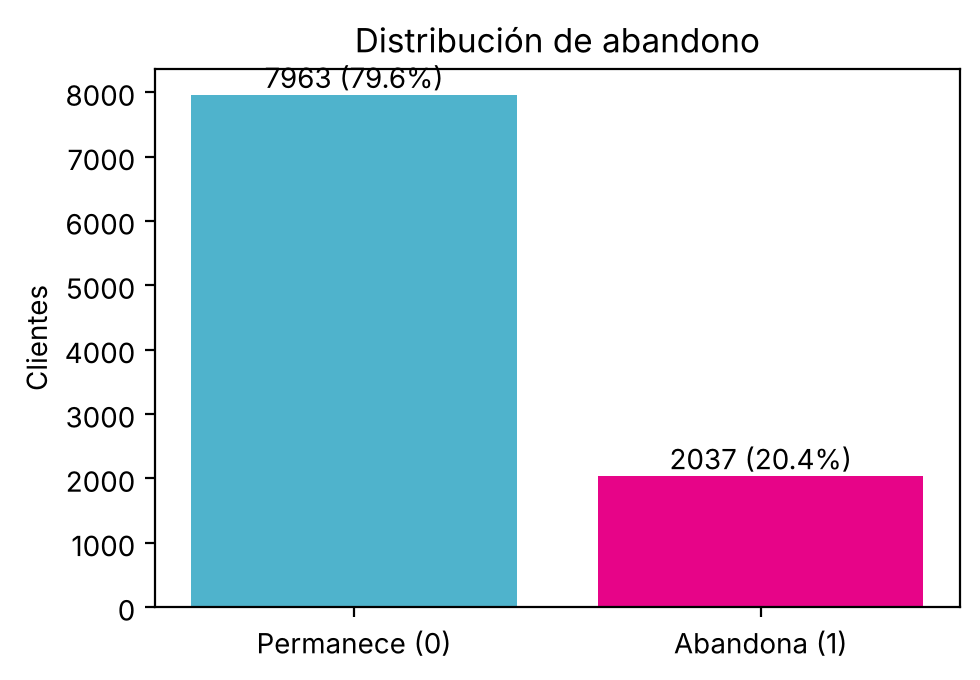

In [5]:
conteo = df["abandono"].value_counts().sort_index()
proporcion = df["abandono"].value_counts(normalize=True).sort_index()
print(pd.DataFrame({"conteo": conteo, "proporción": proporcion.round(4)}))

fig, ax = plt.subplots(figsize=(5, 3.5))
ax.bar(["Permanece (0)", "Abandona (1)"], conteo.values, color=["#4FB3CC", "#E70488"])
for i, v in enumerate(conteo.values):
    ax.text(i, v, f"{v} ({proporcion.values[i]:.1%})", ha="center", va="bottom")
ax.set_title("Distribución de abandono")
ax.set_ylabel("Clientes")
plt.tight_layout(); plt.show()

                      count       mean       std     min       25%        50%        75%        max
edad                10000.0      38.92     10.49   18.00     32.00      37.00      44.00      92.00
puntaje_crediticio  10000.0     650.53     96.65  350.00    584.00     652.00     718.00     850.00
saldo               10000.0   76485.89  62397.41    0.00      0.00   97198.54  127644.24  250898.09
salario_estimado    10000.0  100090.24  57510.49   11.58  51002.11  100193.92  149388.25  199992.48


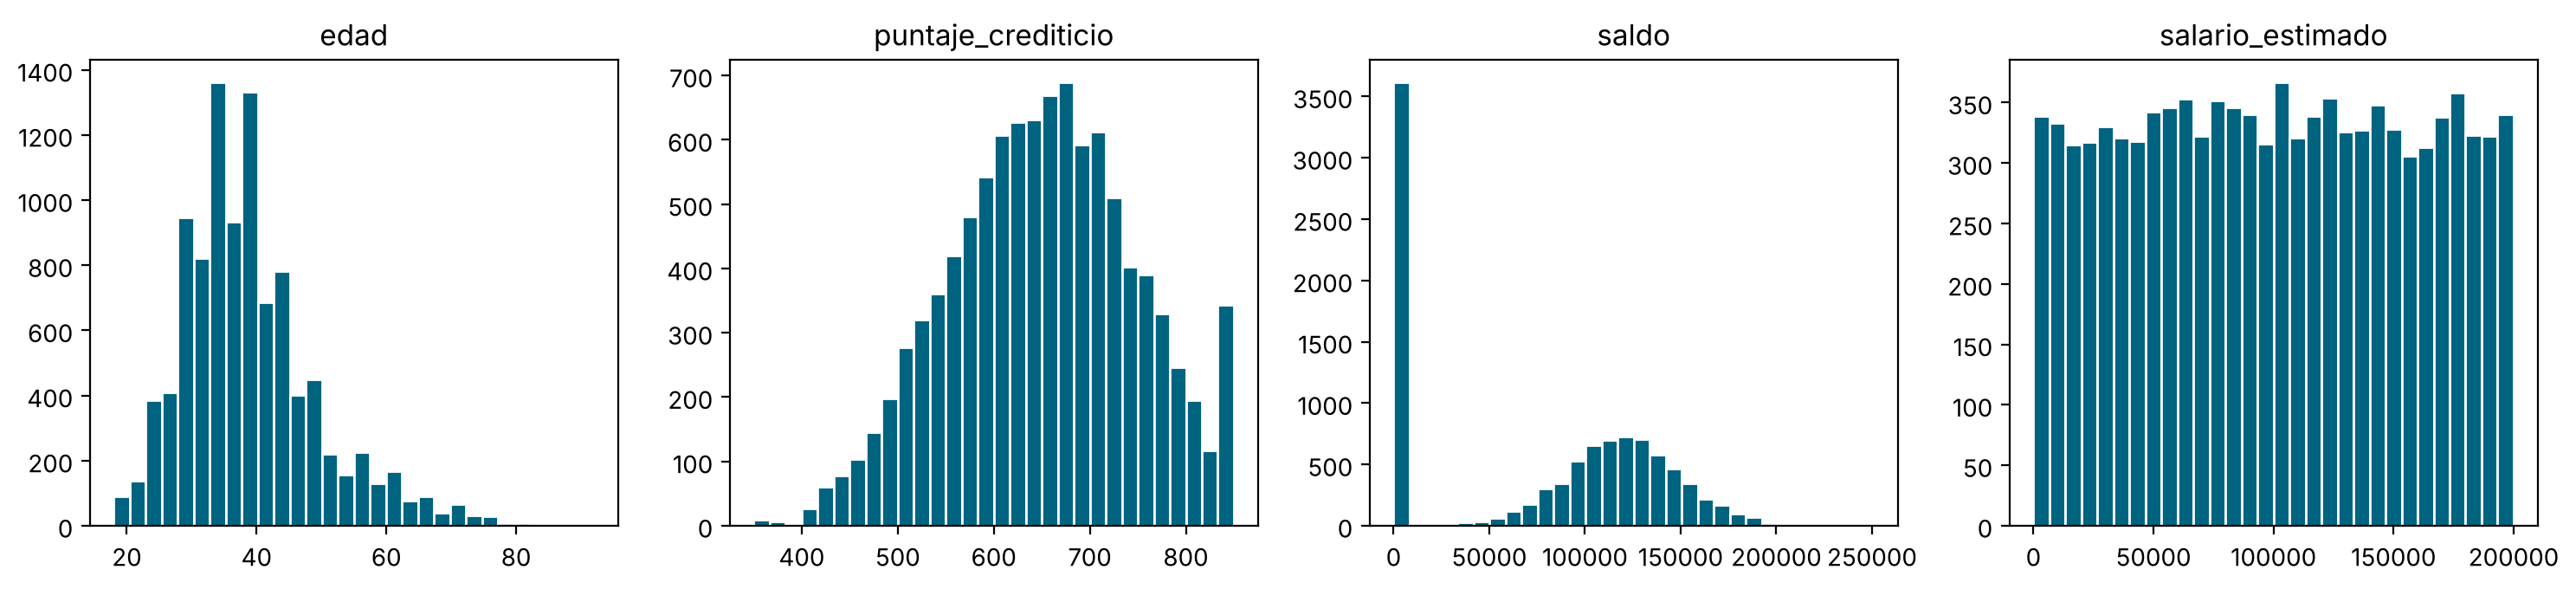

Clientes con saldo = 0: 3617 (36.2%)


In [6]:
continuas = ["edad", "puntaje_crediticio", "saldo", "salario_estimado"]
print(df[continuas].describe().T.round(2))

fig, ejes = plt.subplots(1, 4, figsize=(15, 3.5))
for ax, v in zip(ejes, continuas):
    ax.hist(df[v], bins=30, color="#00637F", edgecolor="white")
    ax.set_title(v)
plt.tight_layout(); plt.show()

print("Clientes con saldo = 0:", int((df["saldo"] == 0).sum()), f"({(df['saldo'] == 0).mean():.1%})")

In [7]:
for v in ["pais", "sexo", "numero_productos", "miembro_activo"]:
    t = pd.DataFrame({"conteo": df[v].value_counts().sort_index(),
                      "proporción": df[v].value_counts(normalize=True).sort_index().round(4)})
    print(f"--- {v} ---")
    print(t, "\n")

--- pais ---
          conteo  proporción
pais                        
Francia     5014      0.5014
Alemania    2509      0.2509
España      2477      0.2477 

--- sexo ---
        conteo  proporción
sexo                      
Mujer     4543      0.4543
Hombre    5457      0.5457 

--- numero_productos ---
                  conteo  proporción
numero_productos                    
1                   5084      0.5084
2                   4590      0.4590
3                    266      0.0266
4                     60      0.0060 

--- miembro_activo ---
                conteo  proporción
miembro_activo                    
0                 4849      0.4849
1                 5151      0.5151 



### Respuesta — Sección 2

**5. ¿Qué porcentaje de la base abandonó? ¿Por qué un clasificador que siempre diga «permanece» ya parece bueno si uno solo mira la *accuracy*?**
Abandonaron **2.037 de 10.000 clientes, el 20,4 %**. El 79,6 % permanece. Un clasificador que diga siempre «permanece» acierta en el 79,6 % de los casos sin usar ninguna variable. Esa exactitud parece alta, pero su sensibilidad es **0**: no detecta a ninguno de los clientes que se van, que son justamente los que le importan al área de retención. Con clases desbalanceadas, la exactitud premia acertar la clase mayoritaria. Por eso hay que mirarla junto con la sensibilidad y la especificidad (sección 6).

Otros rasgos del univariado: la edad tiene sesgo a la derecha (mediana 37, máximo 92). El saldo tiene una masa grande en cero (3.617 clientes, 36,2 %) y luego una campana alrededor de 120.000. El puntaje crediticio y el salario estimado no muestran nada raro: el salario es casi uniforme entre 0 y 200.000. Francia concentra la mitad de los clientes, y el 97 % de la base tiene 1 o 2 productos.

## 3. Bivariado con la respuesta

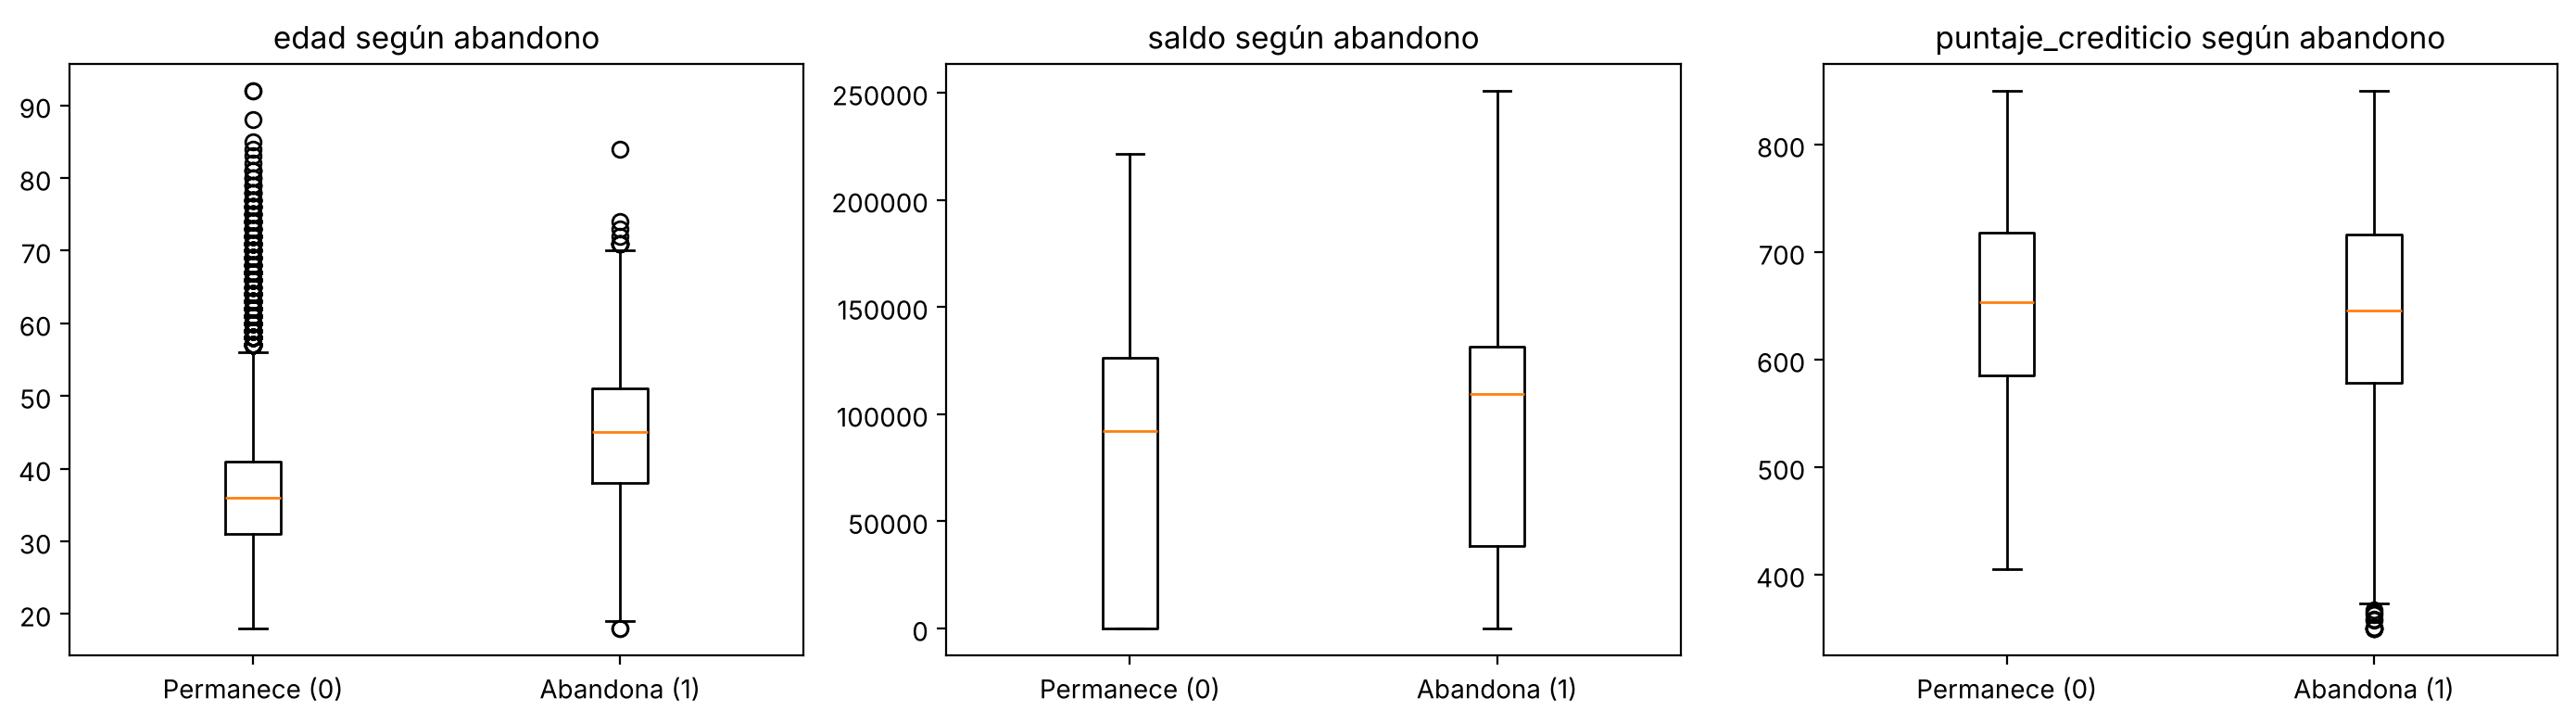

Medianas por grupo
          edad      saldo  puntaje_crediticio
abandono                                     
0         36.0   92072.68               653.0
1         45.0  109349.29               646.0

Medias por grupo
           edad     saldo  puntaje_crediticio
abandono                                     
0         37.41  72745.30              651.85
1         44.84  91108.54              645.35


In [8]:
fig, ejes = plt.subplots(1, 3, figsize=(14, 4))
for ax, v in zip(ejes, ["edad", "saldo", "puntaje_crediticio"]):
    datos = [df.loc[df["abandono"] == k, v] for k in (0, 1)]
    ax.boxplot(datos, tick_labels=["Permanece (0)", "Abandona (1)"])
    ax.set_title(f"{v} según abandono")
plt.tight_layout(); plt.show()

print("Medianas por grupo")
print(df.groupby("abandono")[["edad", "saldo", "puntaje_crediticio"]].median())
print("\nMedias por grupo")
print(df.groupby("abandono")[["edad", "saldo", "puntaje_crediticio"]].mean().round(2))

In [9]:
print("Proporción con saldo 0 por grupo:")
print(df.groupby("abandono")["saldo"].apply(lambda s: (s == 0).mean()).round(3))
print("\nTasa de abandono por tramo de edad:")
tramos = pd.cut(df["edad"], bins=[17, 30, 40, 50, 60, 100], labels=["18-30", "31-40", "41-50", "51-60", "61+"])
print(df.groupby(tramos, observed=True)["abandono"].agg(["mean", "size"]).round(3))

Proporción con saldo 0 por grupo:
abandono
0    0.391
1    0.245
Name: saldo, dtype: float64

Tasa de abandono por tramo de edad:
        mean  size
edad              
18-30  0.075  1968
31-40  0.121  4451
41-50  0.340  2320
51-60  0.562   797
61+    0.248   464


In [10]:
resultados_chi2 = []
for v in ["miembro_activo", "numero_productos", "pais", "sexo", "tiene_tarjeta"]:
    tabla = pd.crosstab(df[v], df["abandono"])
    chi2, p, gl, _ = chi2_contingency(tabla)
    n = tabla.values.sum()
    v_cramer = np.sqrt(chi2 / (n * (min(tabla.shape) - 1)))
    resultados_chi2.append({"variable": v, "chi2": round(chi2, 1), "gl": gl, "p_valor": p, "V_Cramer": round(v_cramer, 3)})
    print(f"--- {v} ---")
    print(pd.concat([tabla, pd.crosstab(df[v], df["abandono"], normalize="index").round(3)
                     .rename(columns={0: "% perm.", 1: "% aband."})], axis=1))
    print(f"chi2 = {chi2:.1f}, gl = {gl}, p = {p:.3g}\n")
pd.DataFrame(resultados_chi2).sort_values("chi2", ascending=False)

--- miembro_activo ---
abandono           0     1  % perm.  % aband.
miembro_activo                               
0               3547  1302    0.731     0.269
1               4416   735    0.857     0.143
chi2 = 243.0, gl = 1, p = 8.79e-55

--- numero_productos ---
abandono             0     1  % perm.  % aband.
numero_productos                               
1                 3675  1409    0.723     0.277
2                 4242   348    0.924     0.076
3                   46   220    0.173     0.827
4                    0    60    0.000     1.000
chi2 = 1503.6, gl = 3, p = 0

--- pais ---
abandono     0    1  % perm.  % aband.
pais                                  
Francia   4204  810    0.838     0.162
Alemania  1695  814    0.676     0.324
España    2064  413    0.833     0.167
chi2 = 301.3, gl = 2, p = 3.83e-66

--- sexo ---
abandono     0     1  % perm.  % aband.
sexo                                   
Mujer     3404  1139    0.749     0.251
Hombre    4559   898    0.835     0.1

,variable,chi2,gl,p_valor,V_Cramer
1,numero_productos,1503.6,3,0.000000e+00,0.388
2,pais,301.3,2,3.830318e-66,0.174
0,miembro_activo,243.0,1,8.785858e-55,0.156
3,sexo,112.9,1,2.248210e-26,0.106
4,tiene_tarjeta,0.5,1,4.923724e-01,0.007


### Respuestas — Sección 3

**6. Distribución de edad entre quien abandona y quien permanece.**
Quien abandona es claramente mayor. La mediana de edad es **45 años** entre los que se van y **36** entre los que se quedan (medias 44,8 y 37,4). En el *boxplot*, la caja de los que abandonan está desplazada hacia arriba: su cuartil inferior (38 años) queda por encima de la mediana de los que permanecen (36), y su cuartil superior llega a 51 frente a 41. Por tramos, la tasa de abandono sube de 7,5 % (18–30 años) a 12,1 % (31–40), 34,0 % (41–50) y **56,2 % (51–60)**, y vuelve a bajar a 24,8 % después de los 60. La relación es fuerte pero no lineal.

**7. Saldo y puntaje crediticio entre los dos grupos.**
- **Saldo:** quien abandona tiene más saldo. La mediana es 109.349 frente a 92.073 y la media 91.109 frente a 72.745. Parte de la diferencia viene de los saldos en cero: el 39,1 % de los que permanecen tiene saldo 0, frente al 24,5 % de los que se van. Los *boxplots* se solapan bastante.
- **Puntaje crediticio:** prácticamente igual. Mediana de 646 entre los que abandonan y 653 entre los que permanecen (medias 645 y 652), con cajas casi idénticas. El puntaje discrimina muy poco.

**8. `miembro_activo` y abandono.**
Sí: los clientes activos abandonan menos. Entre los inactivos la tasa es **26,9 %** y entre los activos **14,3 %**, casi la mitad. El ji-cuadrado es 243,0 con 1 gl (p ≈ 9·10⁻⁵⁵), así que la asociación no es azar.

**9. `numero_productos` y abandono. ¿Más productos se asocia siempre con menos abandono?**
**No.** La relación tiene forma de U. Con 1 producto abandona el **27,7 %**, con 2 baja a **7,6 %**, pero con 3 sube a **82,7 %** y con 4 llega al **100 %** (60 de 60). Pasar de 1 a 2 productos protege; tener 3 o 4 se asocia con abandono casi seguro, aunque esos grupos son pequeños (266 y 60 clientes). El ji-cuadrado es 1.503,6 con 3 gl (p ≈ 0).

**10. ¿Qué variable parece tener mayor relación con el abandono?**
Entre las categóricas, **`numero_productos`**: tiene el ji-cuadrado más alto (1.503,6) y la mayor V de Cramér (0,39), frente a `pais` (301,3; V = 0,17), `miembro_activo` (243,0; V = 0,16) y `sexo` (112,9; V = 0,11). Las tasas van de 7,6 % a 100 % según el número de productos. `tiene_tarjeta` no tiene relación (20,8 % frente a 20,2 %; p = 0,49). Entre las continuas, la **edad** es la que más separa a los grupos: 9 años de diferencia en la mediana y tasas de 7,5 % a 56,2 % por tramo. En el logit simple su z es 26,6. El puntaje crediticio casi no separa.

## 4. De la recta al logit

Intercept   -0.22278
edad         0.01096
dtype: float64
             Coef.  Std.Err.         z  P>|z|   [0.025   0.975]
Intercept -3.92860   0.10312 -38.09595    0.0 -4.13072 -3.72648
edad       0.06294   0.00237  26.61413    0.0  0.05831  0.06758


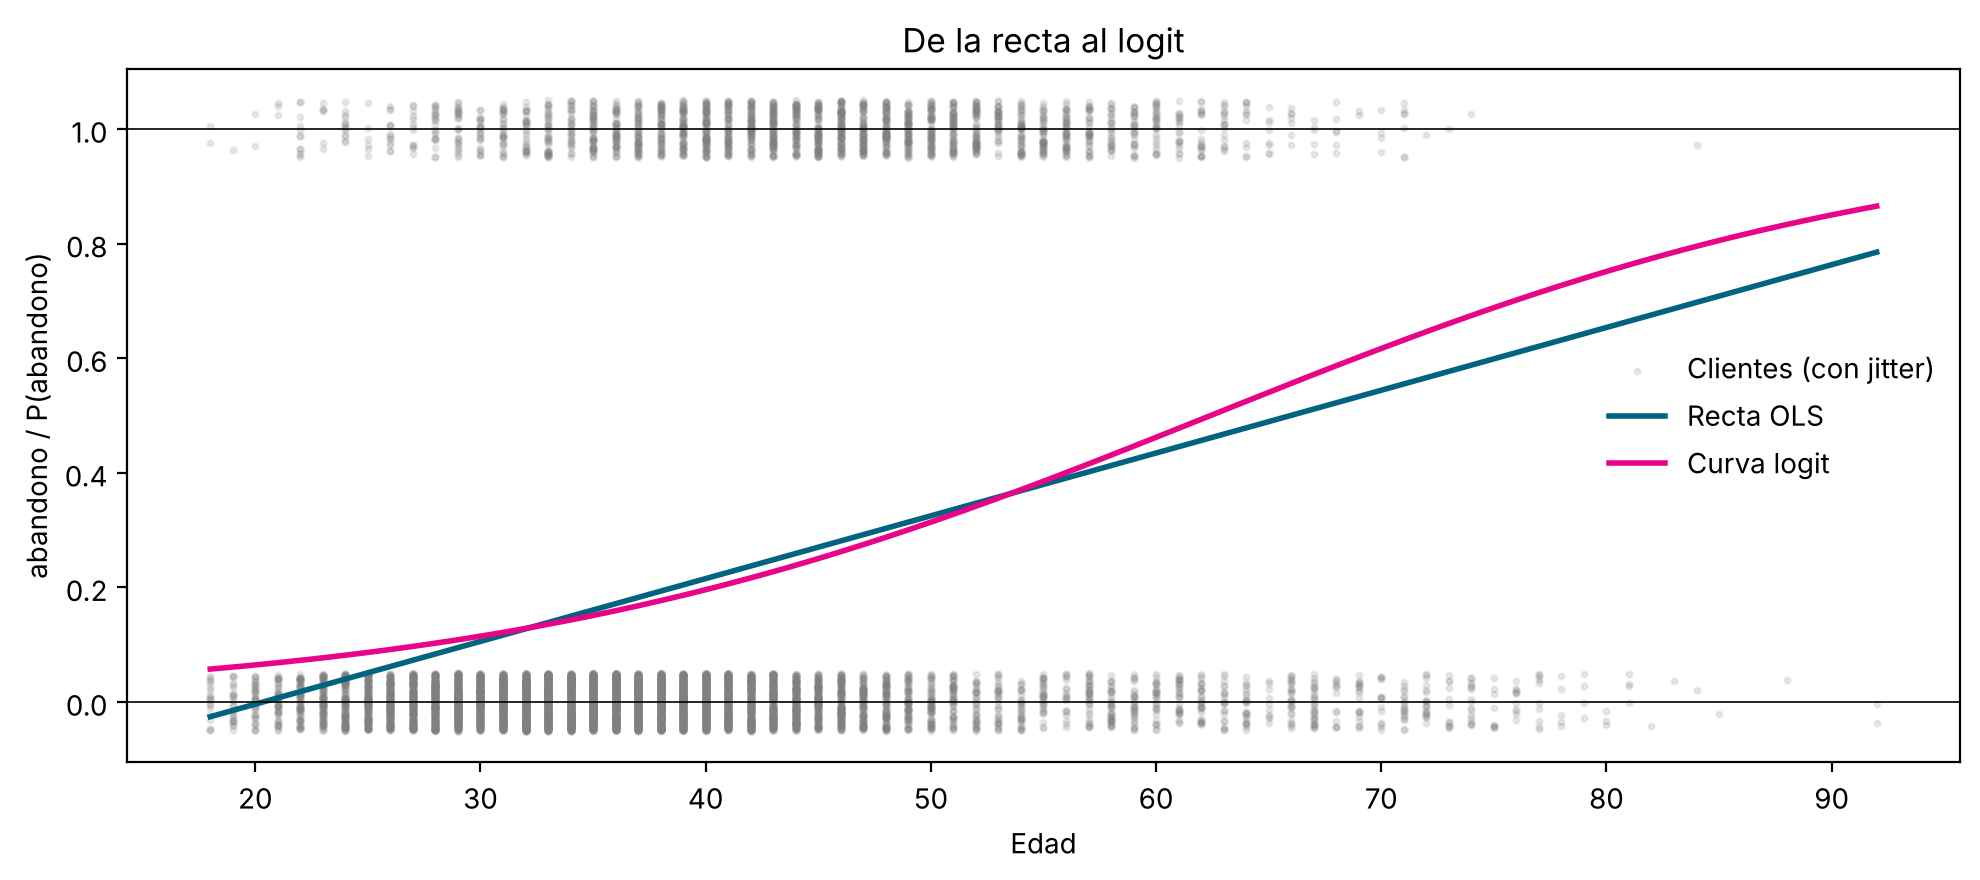

OLS: predicción mínima -0.026 · máxima 0.785
OLS: edad donde la recta cruza 0: 20.3


In [11]:
ols_edad = smf.ols("abandono ~ edad", data=df).fit()
logit_edad = smf.logit("abandono ~ edad", data=df).fit(disp=0)
print(ols_edad.params.round(5))
print(logit_edad.summary2().tables[1].round(5))

rejilla = pd.DataFrame({"edad": np.linspace(df["edad"].min(), df["edad"].max(), 200)})
rng_jitter = np.random.default_rng(0)
y_jitter = df["abandono"] + rng_jitter.uniform(-0.05, 0.05, len(df))

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.scatter(df["edad"], y_jitter, s=4, alpha=0.15, color="grey", label="Clientes (con jitter)")
ax.plot(rejilla["edad"], ols_edad.predict(rejilla), color="#00637F", lw=2, label="Recta OLS")
ax.plot(rejilla["edad"], logit_edad.predict(rejilla), color="#E70488", lw=2, label="Curva logit")
ax.axhline(0, color="black", lw=0.6); ax.axhline(1, color="black", lw=0.6)
ax.set_xlabel("Edad"); ax.set_ylabel("abandono / P(abandono)")
ax.set_title("De la recta al logit")
ax.legend(frameon=False); plt.tight_layout(); plt.show()

pred_ols = ols_edad.predict(rejilla)
print("OLS: predicción mínima", round(pred_ols.min(), 3), "· máxima", round(pred_ols.max(), 3))
print("OLS: edad donde la recta cruza 0:", round(-ols_edad.params["Intercept"] / ols_edad.params["edad"], 1))

In [12]:
b0, b1 = logit_edad.params["Intercept"], logit_edad.params["edad"]
print("Intercepto:", round(b0, 4))
print("Coeficiente de edad:", round(b1, 4))
print("Odds ratio de edad:", round(np.exp(b1), 4))
print("Odds ratio por 10 años:", round(np.exp(10 * b1), 3))
p40 = float(logit_edad.predict(pd.DataFrame({"edad": [40]}))[0])
print("P(abandono | edad = 40):", round(p40, 4))
print("Comprobación a mano:", round(np.exp(b0 + 40 * b1) / (1 + np.exp(b0 + 40 * b1)), 4))

Intercepto: -3.9286
Coeficiente de edad: 0.0629
Odds ratio de edad: 1.065
Odds ratio por 10 años: 1.877
P(abandono | edad = 40): 0.1961
Comprobación a mano: 0.1961


### Respuestas — Sección 4

**11. ¿Por qué la recta de mínimos cuadrados no puede leerse como una probabilidad?**
Porque la recta no está acotada entre 0 y 1. Aquí $\hat y = -0{,}223 + 0{,}011\,\text{edad}$ da valores **negativos para clientes menores de 20,3 años** (−0,026 a los 18). Si la edad sigue subiendo, terminaría pasando de 1. Además, impone un efecto constante: cada año suma 1,1 puntos de probabilidad sin importar si el cliente tiene 20 o 60 años. Los datos muestran otra cosa: la tasa casi no se mueve entre los jóvenes y se dispara entre los 40 y los 60. Los errores de un modelo lineal con y binaria tampoco tienen varianza constante. El logit pasa la combinación lineal por $\Lambda(\cdot)$ y siempre devuelve un valor en (0, 1), con la curva en S del gráfico.

**12. Intercepto, coeficiente de edad y *odds ratio* del logit simple.**
- Intercepto: **−3,9286**
- Coeficiente de edad: **0,0629** (z = 26,6, p < 0,001)
- *Odds ratio*: $e^{0{,}0629}$ = **1,065**

En una frase de negocio: **por cada año adicional de edad, los *odds* de que un cliente cierre su relación con el banco aumentan cerca de 6,5 %**. Diez años más casi duplican los *odds* (OR = 1,88).

**13. P(abandono) para un cliente de 40 años.**
$P = \dfrac{e^{-3{,}9286 + 0{,}0629 \times 40}}{1 + e^{-3{,}9286 + 0{,}0629 \times 40}}$ = **0,196**, es decir, cerca de **19,6 %**. Está muy cerca de la tasa promedio de la base (20,4 %), porque 40 años es una edad algo superior a la media (38,9).

## 5. Varios modelos y *odds ratios*

In [13]:
rng = np.random.default_rng(8)
idx_train = rng.choice(df.index, size=int(0.7 * len(df)), replace=False)
Train_Data = df.loc[idx_train].copy()
Test_Data = df.drop(index=idx_train).copy()
print("Train:", Train_Data.shape, "· Test:", Test_Data.shape)
print("Tasa de abandono · total:", round(df["abandono"].mean(), 4),
      "· train:", round(Train_Data["abandono"].mean(), 4),
      "· test:", round(Test_Data["abandono"].mean(), 4))

Train: (7000, 11) · Test: (3000, 11)
Tasa de abandono · total: 0.2037 · train: 0.2067 · test: 0.1967


In [14]:
formulas = {
    "fit1": "abandono ~ edad",
    "fit2": "abandono ~ edad + puntaje_crediticio",
    "fit3": "abandono ~ edad + puntaje_crediticio + C(sexo)",
    "fit4": "abandono ~ edad + puntaje_crediticio + C(sexo) + C(pais)",
    "fit5": "abandono ~ edad + puntaje_crediticio + C(sexo) + C(pais) + saldo + numero_productos + miembro_activo",
    "fit6": "abandono ~ edad + puntaje_crediticio + C(sexo) + C(pais) + saldo + numero_productos + miembro_activo"
            " + antiguedad + tiene_tarjeta + salario_estimado",
}
ajustes = {k: smf.logit(f, data=Train_Data).fit(disp=0) for k, f in formulas.items()}
comparacion = pd.DataFrame({
    k: {"parámetros": int(m.df_model + 1), "AIC": round(m.aic, 1), "BIC": round(m.bic, 1),
        "pseudo_R2": round(m.prsquared, 4), "logLik": round(m.llf, 1)}
    for k, m in ajustes.items()}).T
comparacion

,parámetros,AIC,BIC,pseudo_R2,logLik
fit1,2.0,6587.9,6601.6,0.0771,-3292.0
fit2,3.0,6581.4,6602.0,0.0783,-3287.7
fit3,4.0,6498.0,6525.4,0.0903,-3245.0
fit4,6.0,6327.8,6368.9,0.1147,-3157.9
fit5,9.0,6021.8,6083.5,0.1584,-3001.9
fit6,12.0,6020.6,6102.8,0.1594,-2998.3


In [15]:
print("p-valores de las tres variables extra en fit6:")
print(ajustes["fit6"].pvalues[["antiguedad", "tiene_tarjeta", "salario_estimado"]].round(4))
lr = 2 * (ajustes["fit6"].llf - ajustes["fit5"].llf)
from scipy.stats import chi2
print(f"\nRazón de verosimilitud fit6 vs fit5: LR = {lr:.2f}, gl = 3, p = {chi2.sf(lr, 3):.4f}")
print("ΔAIC (fit6 − fit5):", round(ajustes["fit6"].aic - ajustes["fit5"].aic, 2))

p-valores de las tres variables extra en fit6:
antiguedad          0.0364
tiene_tarjeta       0.9647
salario_estimado    0.0860
dtype: float64

Razón de verosimilitud fit6 vs fit5: LR = 7.24, gl = 3, p = 0.0645
ΔAIC (fit6 − fit5): -1.24


In [16]:
logit_fits = ajustes["fit5"]
print(logit_fits.summary())

                           Logit Regression Results                           
Dep. Variable:               abandono   No. Observations:                 7000
Model:                          Logit   Df Residuals:                     6991
Method:                           MLE   Df Model:                            8
Date:                Fri, 06 Nov 2026   Pseudo R-squ.:                  0.1584
Time:                        07:33:19   Log-Likelihood:                -3001.9
converged:                       True   LL-Null:                       -3567.0
Covariance Type:            nonrobust   LLR p-value:                1.165e-238
                          coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------
Intercept              -3.2573      0.277    -11.759      0.000      -3.800      -2.714
C(sexo)[T.Hombre]      -0.5547      0.065     -8.527      0.000      -0.682      -0.427
C(pais)[T.Aleman

In [17]:
tabla_or = pd.DataFrame({
    "coef": logit_fits.params,
    "odds_ratio": np.exp(logit_fits.params),
    "IC95_inf": np.exp(logit_fits.conf_int()[0]),
    "IC95_sup": np.exp(logit_fits.conf_int()[1]),
    "p_valor": logit_fits.pvalues,
})
tabla_or["lectura"] = np.where(tabla_or["odds_ratio"] > 1, "riesgo", "protector")
tabla_or.loc["Intercept", "lectura"] = "—"
print(tabla_or.round(4))
print("\nOR por escalas legibles:")
print("  edad +10 años:", round(np.exp(10 * logit_fits.params["edad"]), 3))
print("  puntaje +100:", round(np.exp(100 * logit_fits.params["puntaje_crediticio"]), 3))
print("  saldo +50.000:", round(np.exp(50000 * logit_fits.params["saldo"]), 3))

                       coef  odds_ratio  IC95_inf  IC95_sup  p_valor    lectura
Intercept           -3.2573      0.0385    0.0224    0.0662   0.0000          —
C(sexo)[T.Hombre]   -0.5547      0.5743    0.5055    0.6524   0.0000  protector
C(pais)[T.Alemania]  0.7907      2.2049    1.8815    2.5838   0.0000     riesgo
C(pais)[T.España]    0.0534      1.0548    0.8942    1.2443   0.5266     riesgo
edad                 0.0750      1.0779    1.0713    1.0845   0.0000     riesgo
puntaje_crediticio  -0.0009      0.9991    0.9985    0.9998   0.0098  protector
saldo                0.0000      1.0000    1.0000    1.0000   0.0000     riesgo
numero_productos    -0.1908      0.8263    0.7382    0.9248   0.0009  protector
miembro_activo      -1.0923      0.3354    0.2931    0.3839   0.0000  protector

OR por escalas legibles:
  edad +10 años: 2.117
  puntaje +100: 0.917
  saldo +50.000: 1.138


### Respuestas — Sección 5

**14. ¿Cuántas filas quedan en *train* y en *test*? ¿Se conserva la tasa de abandono?**
**7.000 filas en *train* y 3.000 en *test*.** La tasa de abandono se conserva: 20,7 % en *train*, 19,7 % en *test* y 20,4 % en la base completa. El sorteo con `default_rng(8)` no desbalanceó las clases.

**15. ¿Con qué especificación se queda y por qué? ¿`antiguedad`, `tiene_tarjeta` o `salario_estimado` pagan su puesto?**

| Modelo | Parámetros | AIC | BIC |
|---|---|---|---|
| fit1 | 2 | 6.587,9 | 6.601,6 |
| fit2 | 3 | 6.581,4 | 6.602,0 |
| fit3 | 4 | 6.498,0 | 6.525,4 |
| fit4 | 6 | 6.327,8 | 6.368,9 |
| **fit5** | **9** | **6.021,8** | **6.083,5** |
| fit6 | 12 | 6.020,6 | 6.102,8 |

El AIC cae con fuerza hasta fit5: −84 al sumar sexo, −170 al sumar país y −306 al sumar saldo, productos y miembro activo. Al pasar a fit6 solo baja **1,2 puntos** a cambio de 3 parámetros más. Una diferencia de AIC menor que 2 se considera empate. El BIC, que castiga más los parámetros, prefiere fit5 (6.083,5 frente a 6.102,8). La prueba de razón de verosimilitud de fit6 contra fit5 da LR = 7,24 con 3 gl y **p = 0,065**, así que las tres variables juntas no son significativas al 5 %.
Una por una: `tiene_tarjeta` no aporta nada (p = 0,96, coherente con el ji-cuadrado de la sección 3). `salario_estimado` tampoco (p = 0,086). `antiguedad` está en el borde (p = 0,036), pero su efecto es pequeño y no alcanza a mover el AIC de forma relevante. **Me quedo con fit5 como modelo de trabajo, por parsimonia.** Las tres variables no pagan su puesto.

**16. Factores de riesgo y factores protectores del modelo de trabajo (fit5).**
*Riesgo (OR > 1):*
- **País = Alemania** (OR 2,20; p < 0,001): un cliente en Alemania tiene más del doble de *odds* de abandonar que uno en Francia, con todo lo demás igual.
- **Edad** (OR 1,078 por año; 2,12 por cada 10 años): es el efecto más fuerte entre las continuas.
- **Saldo** (OR 1,138 por cada 50.000; p < 0,001): más dinero en la cuenta se asocia con más abandono. Puede tratarse de clientes con alternativas o que se llevan su dinero.
- *España* (OR 1,05; p = 0,53): no es distinta de Francia.

*Protectores (OR < 1):*
- **Miembro activo** (OR 0,34): estar activo reduce los *odds* de abandono en cerca de 66 %. Es la palanca más clara para retención.
- **Hombre** (OR 0,57): frente a una mujer con el mismo perfil, los *odds* de abandono son 43 % menores.
- **Número de productos** (OR 0,83 por producto): en promedio, cada producto adicional reduce los *odds* en 17 %. Ojo: el modelo lo trata como lineal, y la sección 3 muestra que con 3 o 4 productos el abandono se dispara. Ese OR describe sobre todo el paso de 1 a 2 productos, donde está el 97 % de la base.
- **Puntaje crediticio** (OR 0,917 por cada 100 puntos; p = 0,01): significativo, pero el efecto es pequeño.

## 6. Predicción en test y matriz de confusión

In [18]:
def matriz_e_indicadores(umbral):
    probs = logit_fits.predict(Test_Data)
    pred = np.where(probs > umbral, 1, 0)
    tabla = pd.crosstab(pred, Test_Data["abandono"], rownames=["Predicho"], colnames=["Real"])
    tabla = tabla.reindex(index=[0, 1], columns=[0, 1], fill_value=0)
    TN, FN = tabla.loc[0, 0], tabla.loc[0, 1]
    FP, TP = tabla.loc[1, 0], tabla.loc[1, 1]
    ind = {"umbral": umbral, "TP": TP, "TN": TN, "FP": FP, "FN": FN,
           "exactitud": (TP + TN) / (TP + TN + FP + FN),
           "sensibilidad": TP / (TP + FN),
           "especificidad": TN / (TN + FP)}
    return tabla, ind

tabla_05, ind_05 = matriz_e_indicadores(0.5)
print("Umbral 0.5"); print(tabla_05)
tabla_04, ind_04 = matriz_e_indicadores(0.4)
print("\nUmbral 0.4"); print(tabla_04)

indicadores = pd.DataFrame([ind_05, ind_04]).set_index("umbral")
print("\n", indicadores.round(4))
print("\nExactitud del clasificador trivial «siempre permanece» en test:",
      round(1 - Test_Data["abandono"].mean(), 4))

Umbral 0.5
Real         0    1
Predicho           
0         2309  452
1          101  138

Umbral 0.4
Real         0    1
Predicho           
0         2206  382
1          204  208

          TP    TN   FP   FN  exactitud  sensibilidad  especificidad
umbral                                                             
0.5     138  2309  101  452     0.8157        0.2339         0.9581
0.4     208  2206  204  382     0.8047        0.3525         0.9154

Exactitud del clasificador trivial «siempre permanece» en test: 0.8033


### Respuestas — Sección 6

**17. TP, TN, FP y FN en la matriz de test con umbral 0,5.**

| | Real 0 (permanece) | Real 1 (abandona) |
|---|---|---|
| **Predicho 0** | TN = 2.309 | FN = 452 |
| **Predicho 1** | FP = 101 | TP = 138 |

- **TP = 138**: clientes que el modelo marcó en riesgo y efectivamente cerraron la relación. Son los que retención habría podido contactar a tiempo.
- **TN = 2.309**: clientes que el modelo dio por seguros y efectivamente se quedaron. No se gasta en ellos.
- **FP = 101**: clientes marcados en riesgo que se quedaron. Son llamadas o incentivos que no hacían falta.
- **FN = 452**: clientes que el modelo dio por seguros y se fueron. Es el error más caro: abandonos que nadie vio venir.

**18. Exactitud, sensibilidad y especificidad. ¿Qué cambia con umbral 0,4?**

| Umbral | Exactitud | Sensibilidad | Especificidad | TP | FP | FN |
|---|---|---|---|---|---|---|
| 0,5 | **81,6 %** | **23,4 %** | **95,8 %** | 138 | 101 | 452 |
| 0,4 | 80,5 % | 35,3 % | 91,5 % | 208 | 204 | 382 |

Con 0,5 la exactitud es 81,6 %, apenas 1,2 puntos por encima del clasificador trivial «siempre permanece» (80,3 % en *test*). El modelo detecta solo **uno de cada cuatro** clientes que se van (sensibilidad 23,4 %), aunque casi no se equivoca con los que se quedan (especificidad 95,8 %).
Al bajar el umbral a **0,4**, el modelo declara en riesgo a más clientes: los TP suben de 138 a 208 y la sensibilidad sube a **35,3 %**, es decir, 70 abandonos más detectados. A cambio, los FP se duplican (101 → 204), la especificidad cae a 91,5 % y la exactitud baja a 80,5 %. Para retención, donde un FN (un cliente perdido) cuesta más que un FP (una llamada de más), el umbral 0,4 es preferible aunque la exactitud baje. El umbral es una decisión de negocio, no del modelo.

## 7. Perfiles

In [19]:
perfiles = pd.DataFrame({
    "sexo": pd.Categorical(["Mujer", "Hombre"], categories=["Mujer", "Hombre"]),
    "pais": pd.Categorical(["Francia", "España"], categories=["Francia", "Alemania", "España"]),
    "edad": [40, 30],
    "puntaje_crediticio": [650, 720],
    "antiguedad": [5, 6],
    "saldo": [100000, 50000],
    "numero_productos": [1, 2],
    "tiene_tarjeta": [0, 1],
    "miembro_activo": [0, 1],
    "salario_estimado": [100000, 80000],
}, index=["Perfil A", "Perfil B"])
perfiles["P_abandono"] = logit_fits.predict(perfiles)
print(perfiles.T)

                    Perfil A  Perfil B
sexo                   Mujer    Hombre
pais                 Francia    España
edad                      40        30
puntaje_crediticio       650       720
antiguedad                 5         6
saldo                 100000     50000
numero_productos           1         2
tiene_tarjeta              0         1
miembro_activo             0         1
salario_estimado      100000     80000
P_abandono          0.320403  0.029987


In [20]:
# Contribución de cada variable al log-odds de A frente a B (modelo de trabajo)
from patsy import dmatrix
M = dmatrix(formulas["fit5"].split("~")[1], perfiles, return_type="dataframe")[logit_fits.params.index]
contrib = (M * logit_fits.params).T
contrib["A − B"] = contrib["Perfil A"] - contrib["Perfil B"]
print(contrib.round(3))
print("\nLog-odds:", (M @ logit_fits.params).round(3).to_dict())

                     Perfil A  Perfil B  A − B
Intercept              -3.257    -3.257  0.000
C(sexo)[T.Hombre]      -0.000    -0.555  0.555
C(pais)[T.Alemania]     0.000     0.000  0.000
C(pais)[T.España]       0.000     0.053 -0.053
edad                    3.001     2.251  0.750
puntaje_crediticio     -0.563    -0.624  0.061
saldo                   0.259     0.129  0.129
numero_productos       -0.191    -0.382  0.191
miembro_activo         -0.000    -1.092  1.092

Log-odds: {'Perfil A': -0.752, 'Perfil B': -3.477}


### Respuestas — Sección 7

Probabilidades estimadas con el modelo de trabajo (fit5). `antiguedad`, `tiene_tarjeta` y `salario_estimado` aparecen en los perfiles pero no entran a fit5, así que no cambian la probabilidad.

**19. Probabilidad del perfil A:** **0,320 (32,0 %)**. Mujer, Francia, 40 años, puntaje 650, saldo 100.000, 1 producto, inactiva.

**20. Probabilidad del perfil B:** **0,030 (3,0 %)**. Hombre, España, 30 años, puntaje 720, saldo 50.000, 2 productos, activo.

**21. ¿Cuál es más riesgoso y por qué?**
**El perfil A**: su probabilidad de abandono es unas 10 veces la de B, y está por encima de la tasa promedio de la base (20,4 %). B queda muy por debajo. El log-odds de A es −0,75 y el de B −3,48. La diferencia de 2,72 se reparte así:
- **Miembro activo** (+1,09): A está inactiva y B activo. Es el factor que más empuja.
- **Edad** (+0,75): A tiene 10 años más (OR 2,12 por década).
- **Sexo** (+0,55): A es mujer, la categoría con más abandono.
- **Número de productos** (+0,19): A tiene 1 producto y B tiene 2.
- **Saldo** (+0,13): A tiene el doble de saldo.
- **Puntaje** (+0,06): A tiene 70 puntos menos.
- **País** (−0,05): España frente a Francia casi no cambia nada y es lo único que juega levemente a favor de A.

Lectura para retención: A reúne los cuatro factores más fuertes del modelo (inactividad, edad, sexo y un solo producto). Sería prioridad de contacto con cualquiera de los dos umbrales. B tiene todos los protectores activos.

## 8. Más allá del taller: ROC, no linealidades, umbral por costos y deciles

In [21]:
# 8.1 Curva ROC y AUC del modelo de trabajo en test
probs_test = logit_fits.predict(Test_Data)
y_test = Test_Data["abandono"].values

def curva_roc(y, p):
    umbrales = np.r_[1.01, np.sort(np.unique(p))[::-1], 0.0]
    tpr = np.array([((p >= u) & (y == 1)).sum() / (y == 1).sum() for u in umbrales])
    fpr = np.array([((p >= u) & (y == 0)).sum() / (y == 0).sum() for u in umbrales])
    return fpr, tpr

def auc(y, p):
    # Probabilidad de que un cliente que abandona tenga mayor score que uno que permanece
    pos, neg = p[y == 1], p[y == 0]
    rangos = pd.Series(np.r_[pos, neg]).rank().values
    return (rangos[: len(pos)].sum() - len(pos) * (len(pos) + 1) / 2) / (len(pos) * len(neg))

fpr5, tpr5 = curva_roc(y_test, probs_test.values)
auc_fit5 = auc(y_test, probs_test.values)
print("AUC del modelo de trabajo (fit5) en test:", round(auc_fit5, 4))

AUC del modelo de trabajo (fit5) en test: 0.755


                        Coef.   P>|z|
Intercept             -9.1795  0.0000
C(sexo)[T.Hombre]     -0.5712  0.0000
C(pais)[T.Alemania]    0.9223  0.0000
C(pais)[T.España]      0.0981  0.2878
C(productos_cat)[T.2] -1.5716  0.0000
C(productos_cat)[T.3]  2.8204  0.0000
edad                   0.3241  0.0000
I(edad ** 2)          -0.0022  0.0000
puntaje_crediticio    -0.0009  0.0216
saldo                 -0.0000  0.4845
miembro_activo         1.9264  0.0000
edad:miembro_activo   -0.0697  0.0000

AIC fit5: 6021.8 · AIC extendido: 5014.7
BIC fit5: 6083.5 · BIC extendido: 5097.0



AUC en test · fit5: 0.755 · extendido: 0.8382


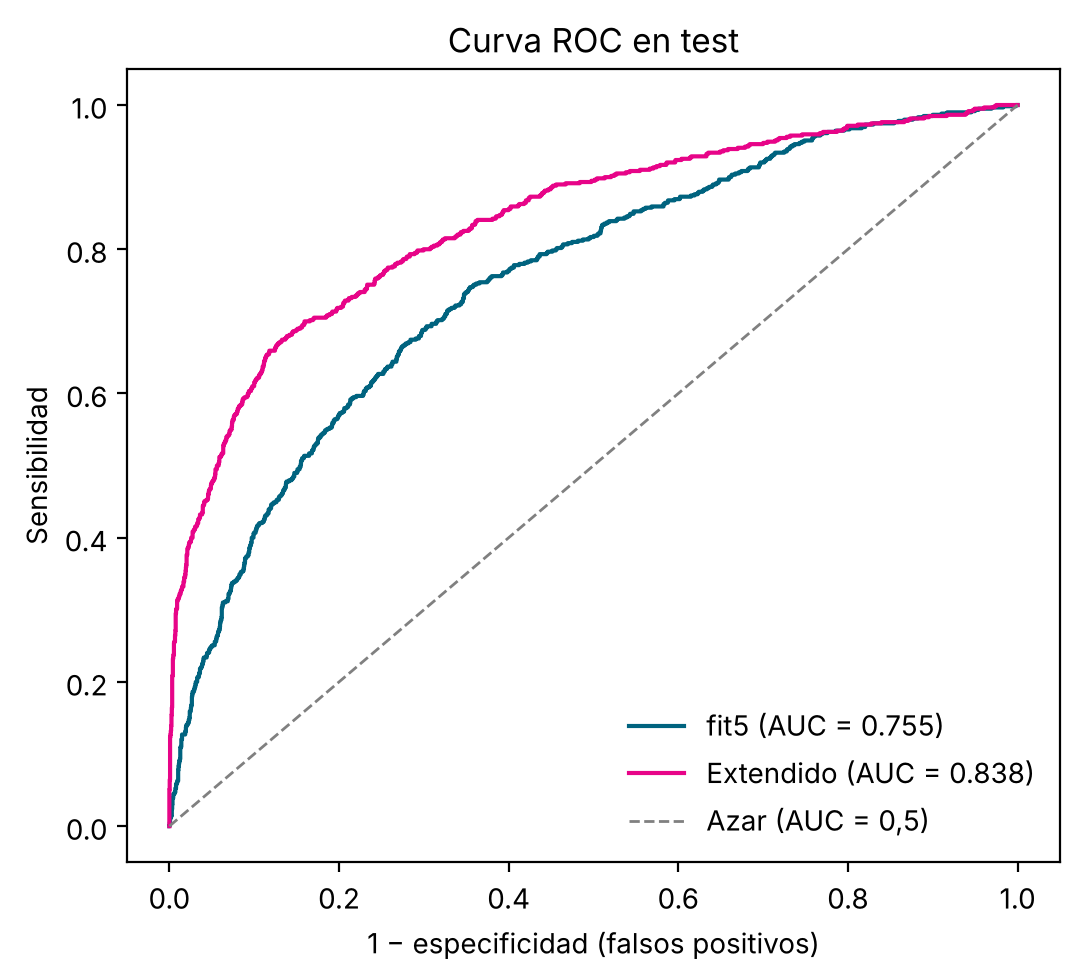

In [22]:
# 8.2 Modelo extendido: no linealidades que el bivariado ya mostraba
# - edad tiene forma de U invertida (sube hasta ~55 años y luego baja)  -> edad + edad²
# - numero_productos no es lineal (2 protege, 3 y 4 disparan el abandono) -> como factor
# - ¿estar inactivo pesa distinto según la edad? -> interacción edad × miembro_activo
Train_Data["productos_cat"] = pd.Categorical(Train_Data["numero_productos"].clip(upper=3), categories=[1, 2, 3])
Test_Data["productos_cat"] = pd.Categorical(Test_Data["numero_productos"].clip(upper=3), categories=[1, 2, 3])

formula_ext = ("abandono ~ edad + I(edad**2) + puntaje_crediticio + C(sexo) + C(pais) + saldo"
               " + C(productos_cat) + miembro_activo + edad:miembro_activo")
logit_ext = smf.logit(formula_ext, data=Train_Data).fit(disp=0)
print(logit_ext.summary2().tables[1][["Coef.", "P>|z|"]].round(4))
print("\nAIC fit5:", round(logit_fits.aic, 1), "· AIC extendido:", round(logit_ext.aic, 1))
print("BIC fit5:", round(logit_fits.bic, 1), "· BIC extendido:", round(logit_ext.bic, 1))

probs_ext = logit_ext.predict(Test_Data)
fpr_e, tpr_e = curva_roc(y_test, probs_ext.values)
auc_ext = auc(y_test, probs_ext.values)
print("\nAUC en test · fit5:", round(auc_fit5, 4), "· extendido:", round(auc_ext, 4))

fig, ax = plt.subplots(figsize=(5.5, 5))
ax.plot(fpr5, tpr5, color="#00637F", label=f"fit5 (AUC = {auc_fit5:.3f})")
ax.plot(fpr_e, tpr_e, color="#E70488", label=f"Extendido (AUC = {auc_ext:.3f})")
ax.plot([0, 1], [0, 1], color="grey", ls="--", lw=1, label="Azar (AUC = 0,5)")
ax.set_xlabel("1 − especificidad (falsos positivos)"); ax.set_ylabel("Sensibilidad")
ax.set_title("Curva ROC en test"); ax.legend(frameon=False, loc="lower right")
plt.tight_layout(); plt.show()

Umbral de mínimo costo: 0.26
        costo  sensibilidad  pct_contactados
umbral                                      
0.50     1723         0.451            0.123
0.40     1503         0.549            0.166
0.26     1273         0.700            0.267

Umbral teórico si el modelo está bien calibrado: costo_FP / (costo_FP + costo_FN) = 0.167


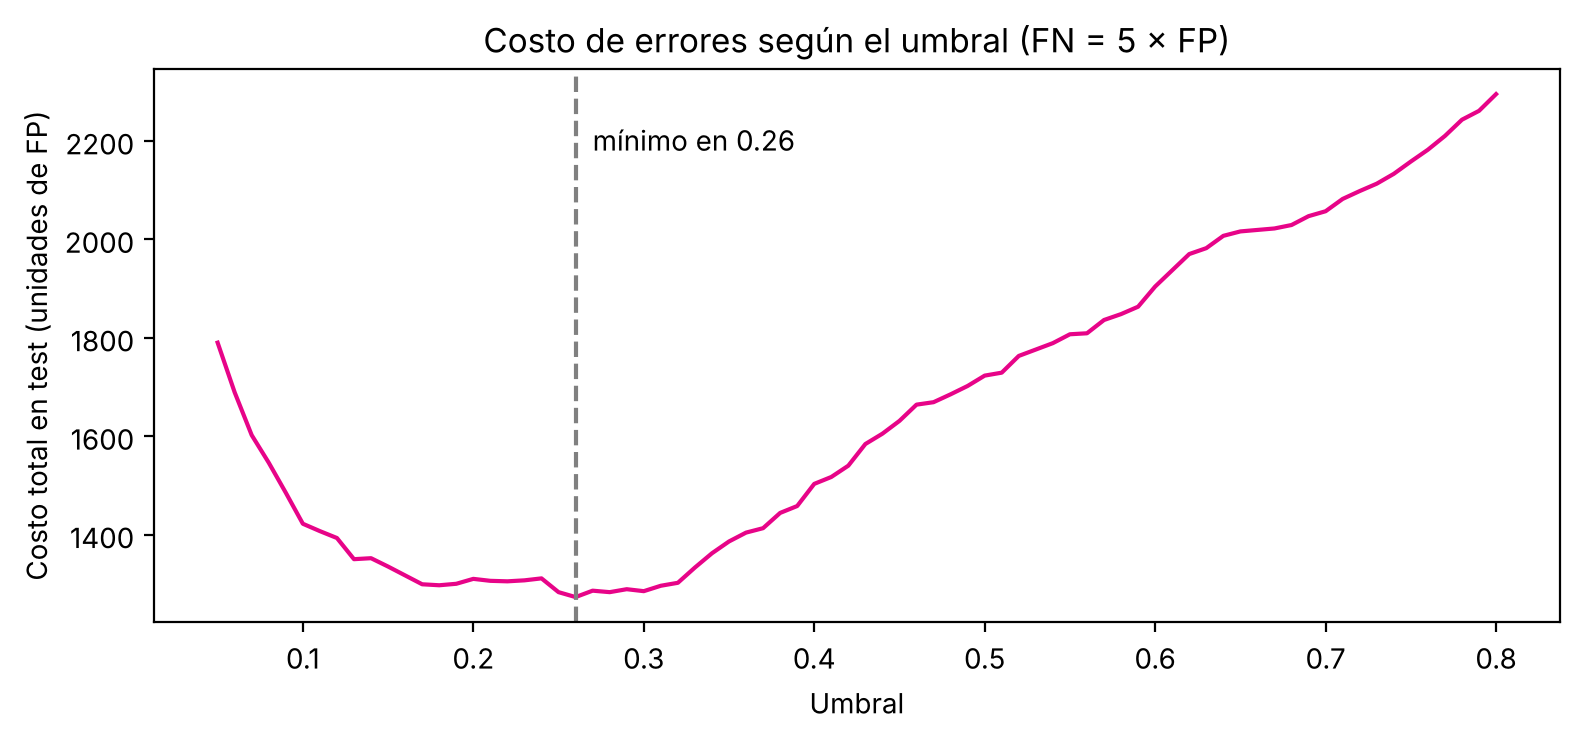

In [23]:
# 8.3 Umbral por costos: ¿dónde conviene cortar para el área de retención?
# Supuesto ilustrativo: perder un cliente (FN) cuesta 5 veces lo que una llamada innecesaria (FP).
costo_FP, costo_FN = 1, 5

def costo_total(p, umbral):
    pred = (p > umbral).astype(int)
    fp = ((pred == 1) & (y_test == 0)).sum()
    fn = ((pred == 0) & (y_test == 1)).sum()
    tp = ((pred == 1) & (y_test == 1)).sum()
    return costo_FP * fp + costo_FN * fn, tp / (y_test == 1).sum(), pred.mean()

rejilla_u = np.round(np.arange(0.05, 0.81, 0.01), 2)
costos = pd.DataFrame([(u, *costo_total(probs_ext.values, u)) for u in rejilla_u],
                      columns=["umbral", "costo", "sensibilidad", "pct_contactados"]).set_index("umbral")
u_opt = costos["costo"].idxmin()
print("Umbral de mínimo costo:", u_opt)
print(costos.loc[[0.5, 0.4, u_opt]].round(3))
print("\nUmbral teórico si el modelo está bien calibrado: costo_FP / (costo_FP + costo_FN) =",
      round(costo_FP / (costo_FP + costo_FN), 3))

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(costos.index, costos["costo"], color="#E70488")
ax.axvline(u_opt, color="grey", ls="--"); ax.text(u_opt + 0.01, costos["costo"].max() * 0.95, f"mínimo en {u_opt}")
ax.set_xlabel("Umbral"); ax.set_ylabel("Costo total en test (unidades de FP)")
ax.set_title("Costo de errores según el umbral (FN = 5 × FP)")
plt.tight_layout(); plt.show()

In [24]:
# 8.4 Tabla de ganancia por deciles: a quién llamar primero
deciles = pd.DataFrame({"p": probs_ext.values, "abandono": y_test})
deciles["decil"] = pd.qcut(deciles["p"].rank(method="first", ascending=False), 10, labels=range(1, 11))
ganancia = deciles.groupby("decil", observed=True).agg(clientes=("abandono", "size"),
                                                       abandonos=("abandono", "sum"),
                                                       p_media=("p", "mean"))
ganancia["tasa_real"] = ganancia["abandonos"] / ganancia["clientes"]
ganancia["%_abandonos_capturados_acum"] = ganancia["abandonos"].cumsum() / ganancia["abandonos"].sum()
ganancia["lift"] = ganancia["tasa_real"] / y_test.mean()
print(ganancia.round(3))

       clientes  abandonos  p_media  tasa_real  %_abandonos_capturados_acum   lift
decil                                                                             
1           300        236    0.780      0.787                        0.400  4.000
2           300        124    0.441      0.413                        0.610  2.102
3           300         63    0.284      0.210                        0.717  1.068
4           300         49    0.192      0.163                        0.800  0.831
5           300         36    0.134      0.120                        0.861  0.610
6           300         25    0.094      0.083                        0.903  0.424
7           300         18    0.065      0.060                        0.934  0.305
8           300         15    0.045      0.050                        0.959  0.254
9           300         13    0.027      0.043                        0.981  0.220
10          300         11    0.012      0.037                        1.000  0.186


In [25]:
# 8.5 El modelo extendido frente a fit5: indicadores con umbral 0.5 y los dos perfiles
def indicadores(p, umbral=0.5):
    pred = (p > umbral).astype(int)
    tp = ((pred == 1) & (y_test == 1)).sum(); tn = ((pred == 0) & (y_test == 0)).sum()
    fp = ((pred == 1) & (y_test == 0)).sum(); fn = ((pred == 0) & (y_test == 1)).sum()
    return pd.Series({"TP": tp, "TN": tn, "FP": fp, "FN": fn,
                      "exactitud": (tp + tn) / len(y_test),
                      "sensibilidad": tp / (tp + fn), "especificidad": tn / (tn + fp)})

print(pd.DataFrame({"fit5": indicadores(probs_test.values), "extendido": indicadores(probs_ext.values)}).round(4))

b = logit_ext.params
print("\nOR de estar activo según la edad:")
for e in (30, 40, 50, 60):
    print(f"  {e} años: {np.exp(b['miembro_activo'] + b['edad:miembro_activo'] * e):.3f}")
print("OR 2 productos vs 1:", round(np.exp(b["C(productos_cat)[T.2]"]), 3),
      "· 3 o más vs 1:", round(np.exp(b["C(productos_cat)[T.3]"]), 2))

perfiles["productos_cat"] = pd.Categorical(perfiles["numero_productos"].clip(upper=3), categories=[1, 2, 3])
print("\nP(abandono) de los perfiles:")
print(pd.DataFrame({"fit5": logit_fits.predict(perfiles), "extendido": logit_ext.predict(perfiles)}).round(4))

                    fit5  extendido
TP              138.0000   266.0000
TN             2309.0000  2307.0000
FP              101.0000   103.0000
FN              452.0000   324.0000
exactitud         0.8157     0.8577
sensibilidad      0.2339     0.4508
especificidad     0.9581     0.9573

OR de estar activo según la edad:
  30 años: 0.849
  40 años: 0.423
  50 años: 0.211
  60 años: 0.105
OR 2 productos vs 1: 0.208 · 3 o más vs 1: 16.78

P(abandono) de los perfiles:
            fit5  extendido
Perfil A  0.3204     0.4022
Perfil B  0.0300     0.0132


### Sección 8 — Más allá del taller

El taller se queda en un logit lineal con umbral 0,5. Esta sección agrega cuatro cosas que usaría un área de retención real. Todo se calcula con los mismos *train* y *test*.

**8.1 Curva ROC y AUC.** La exactitud depende del umbral; el **AUC** no. Mide la probabilidad de que un cliente que abandona reciba un *score* más alto que uno que permanece. El modelo de trabajo (fit5) tiene **AUC = 0,755** en *test*: ordena bien, aunque con umbral 0,5 solo detectaba el 23 % de los abandonos.

**8.2 Modelo extendido con las no linealidades del bivariado.** La sección 3 mostró dos patrones que fit5 no puede captar:
- La **edad** tiene forma de U invertida: el abandono sube hasta los 51–60 años y luego baja. Se agrega **edad²**.
- **`numero_productos`** no es lineal: 2 productos protegen y 3 o 4 disparan el abandono. Se trata como **factor** (1, 2 y 3 o más).
- Además se agrega la interacción **edad × miembro_activo**, para probar si la inactividad pesa distinto según la edad.

Resultado: el AIC cae de **6.021,8 a 5.014,7** (−1.007) y el BIC de 6.083,5 a 5.097,0. En *test* el AUC sube de **0,755 a 0,838**. Con el mismo umbral 0,5, la sensibilidad pasa de 23,4 % a **45,1 %** y la exactitud de 81,6 % a **85,8 %**, sin perder especificidad (95,7 %).
Lo que dicen los nuevos coeficientes:
- Frente a 1 producto, tener **2 productos** multiplica los *odds* por **0,21** (protector fuerte) y tener **3 o más** por **16,8** (riesgo extremo). El OR lineal de 0,83 de fit5 promediaba dos efectos opuestos.
- El efecto de estar **activo** depende de la edad: su OR es 0,85 a los 30 años, 0,42 a los 40, 0,21 a los 50 y **0,11 a los 60**. Activar a un cliente mayor reduce mucho más su riesgo que activar a uno joven.
- Con estos términos, el **saldo** deja de ser significativo (p = 0,48). Su efecto en fit5 probablemente recogía la relación con los productos.

**8.3 Umbral por costos.** Elegir 0,5 o 0,4 es arbitrario. Si perder un cliente cuesta 5 veces lo que una llamada innecesaria (supuesto ilustrativo), el umbral que minimiza el costo en *test* es **0,26**. Con él se contacta al 26,7 % de la cartera y se detecta el **70 %** de los abandonos. El costo baja de 1.723 (umbral 0,5) a **1.273**, un 26 % menos. La teoría da 1/(1+5) ≈ 0,17 si el modelo estuviera perfectamente calibrado; la diferencia indica que las probabilidades no están del todo calibradas.

**8.4 Deciles: a quién llamar primero.** Al ordenar a los 3.000 clientes de *test* por probabilidad, el **10 % más riesgoso** tiene una tasa real de abandono de **78,7 %**, cuatro veces la tasa promedio (*lift* = 4,0), y concentra el **40 %** de todos los abandonos. Llamando solo al 20 % de arriba se captura el 61 %, y con el 30 % se llega al 72 %. Es la forma práctica de usar el modelo cuando el presupuesto de llamadas es limitado.

**Perfiles con el modelo extendido.** El perfil A sube de 32,0 % a **40,2 %** y el B baja de 3,0 % a **1,3 %**. La diferencia entre ambos se amplía porque el modelo extendido reconoce que 2 productos protegen mucho más de lo que suponía la recta, y que la inactividad pesa más a los 40 años que a los 30.

**Conclusión.** El logit del taller ordena razonablemente, pero tratar como lineales variables que no lo son le cuesta mucho. Usar lo que mostró el análisis bivariado (edad², productos como factor e interacción con actividad) mejora todas las métricas fuera de muestra. El umbral debería salir de los costos del negocio, no de un 0,5 por defecto.